## Seaborn

pandas + Matplotlib = Seaborn

easily create the most common plot types

keeps the code simple


In [40]:
import seaborn as sns
import matplotlib.pyplot as plt
import os
import numpy as np
import pandas as pd

### Scatterplot

<Axes: >

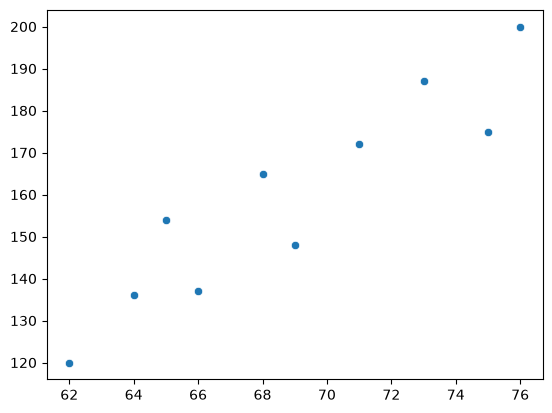

In [21]:
height = [62, 64, 69, 75, 66, 68, 65, 71, 76, 73]
weight = [120, 136, 148, 175, 137, 165, 154, 172, 200, 187]

sns.scatterplot(x=height, y=weight)


This shows that taller people tend to have higher weight.

### Count plot

This plot takes in a categorical list and return bars that represent the number of list entries per category. 

<Axes: ylabel='count'>

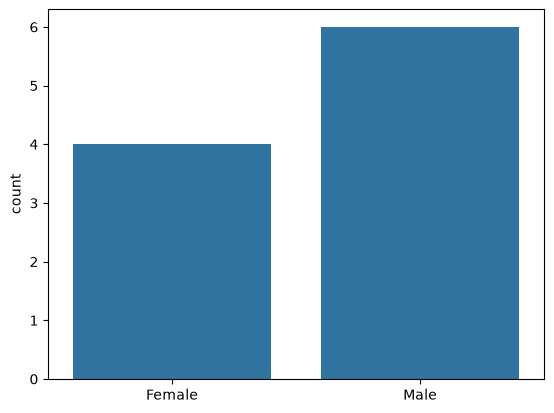

In [22]:
gender = ['Female', 'Female',
           'Female', 'Female', 
           'Male', 'Male', 'Male',
             'Male', 'Male', 'Male']
sns.countplot(x=gender)

<Axes: xlabel='count'>

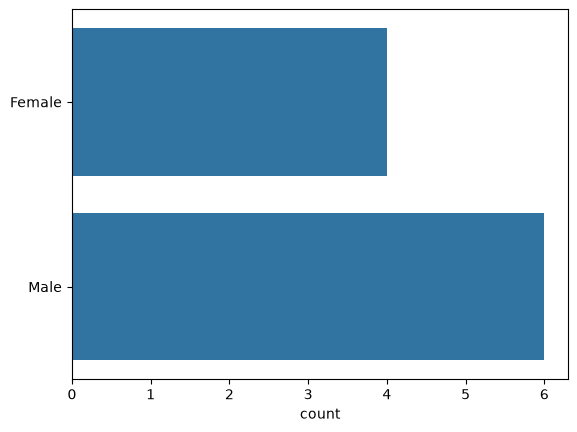

In [23]:
sns.countplot(y=gender)

In [24]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("fivethirtyeight/fivethirtyeight-masculinity-survey-dataset")

print("Path to dataset files:", path)

csv_path = os.path.join(path, 'masculinity-survey.csv')

df = pd.read_csv(csv_path)

Path to dataset files: /home/jubel/.cache/kagglehub/datasets/fivethirtyeight/fivethirtyeight-masculinity-survey-dataset/versions/111


In [25]:
df.info

<bound method DataFrame.info of                                        AMONG ADULT MEN          Unnamed: 1  \
0                                                  NaN                 NaN   
1    In general, how masculine or "manly" do you feel?                 NaN   
2                                                  NaN      Very masculine   
3                                                  NaN  Somewhat masculine   
4                                                  NaN  Not very masculine   
..                                                 ...                 ...   
227                                               age3                 NaN   
228                                                NaN             18 - 34   
229                                                NaN             35 - 64   
230                                                NaN           65 and up   
231                                                NaN                 NaN   

    Adult Men      Age Unnamed:

Untidy DataFrame that would need to be transformed into a tidy one to use with Seaborn...

Always make sure to check if your DataFrame is tidy before using it with Seaborn.

Create a count plot with "Spiders" on the x-axis
sns.countplot(x='Spiders', data=df)

In [26]:
tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### a scatterplot with hue

Scatterplot are good for questions about the relationship between two quantitative variables

height vs weight
number of absences vs final grade


Sometimes we suspect that the relationship may be different within certain subgroups. We can use hue to see subgroups.


<Axes: xlabel='total_bill', ylabel='tip'>

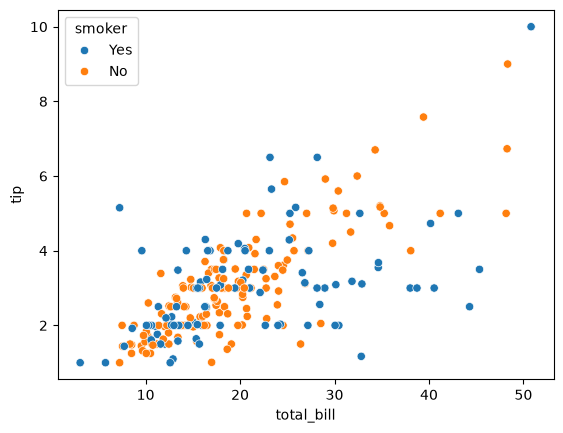

In [27]:
sns.scatterplot(x='total_bill', y='tip', data=tips, 
                hue='smoker', 
                hue_order=['Yes', 'No'])

Seaborn adds a legend automatically. Hue 

### specifying hue colors

<Axes: xlabel='total_bill', ylabel='tip'>

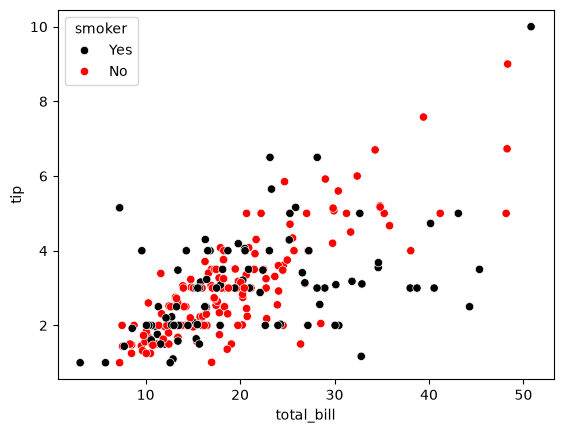

In [28]:
hue_colors = {'Yes': 'black', 'No':'red'}

sns.scatterplot(x='total_bill', y='tip', data=tips, 
                hue='smoker', palette=hue_colors )

tou can use a html hex code instead of color name, there are a lot!

<Axes: xlabel='smoker', ylabel='count'>

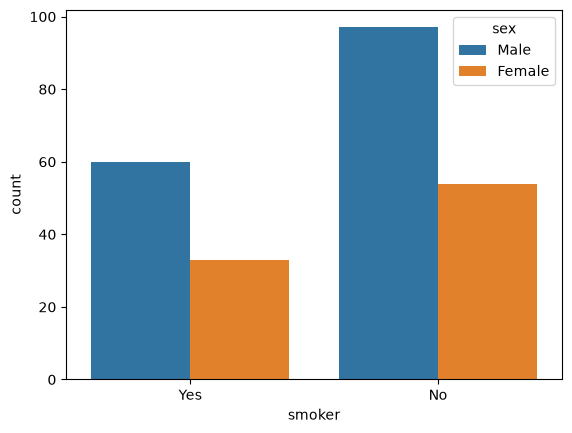

In [29]:
sns.countplot(x='smoker', data=tips, hue='sex')

Now we will create seperate plots for subgroups.

relplot()

create 'relational plot': scatter or line plots

AND it lets you create subplots in a single figure


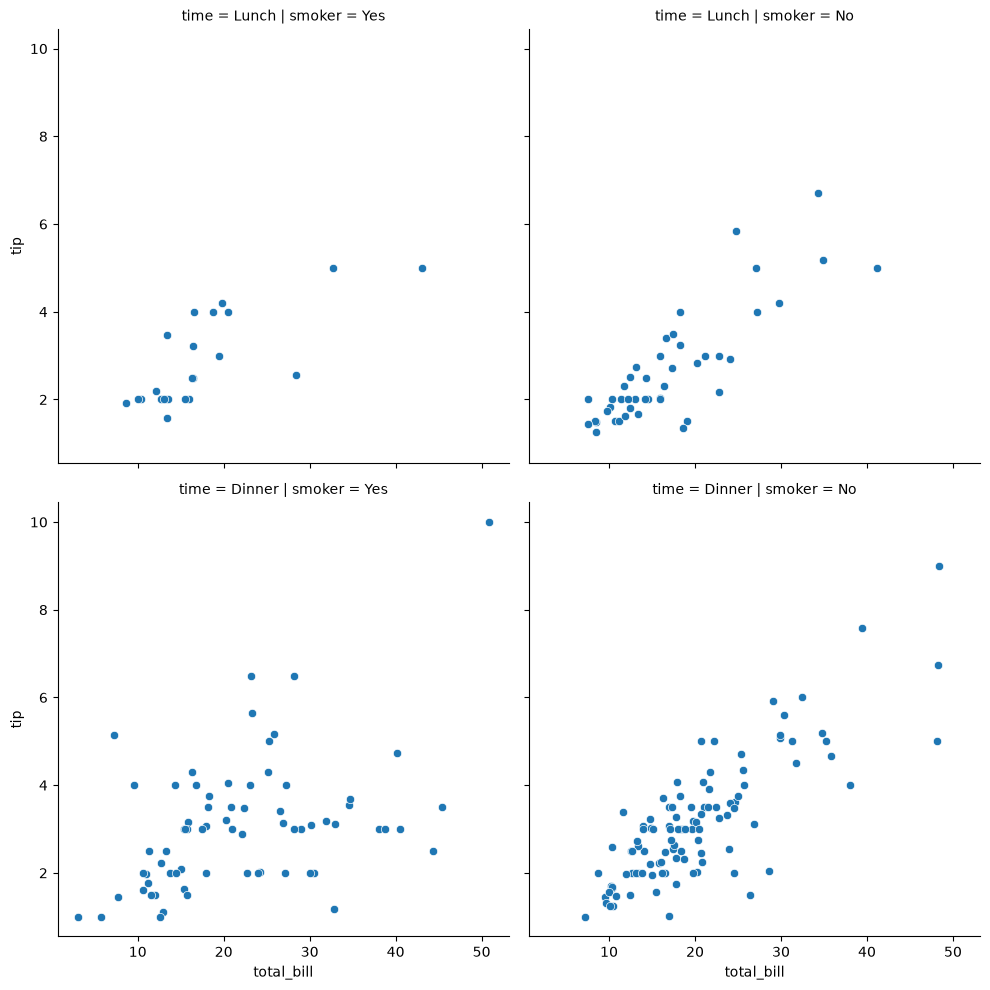

In [30]:
sns.relplot(x='total_bill', y='tip', data=tips, kind='scatter',
            col='smoker',
            row='time') # col='smoker' -> seperate scatter plots

row - aranges subplots vertically in rows
col - arranges horizontally

you can use both!

above you see a subplot for each combination of these two categorical variables.

there is also the 'col_wrap' parameter to specify how many subplots you want per row

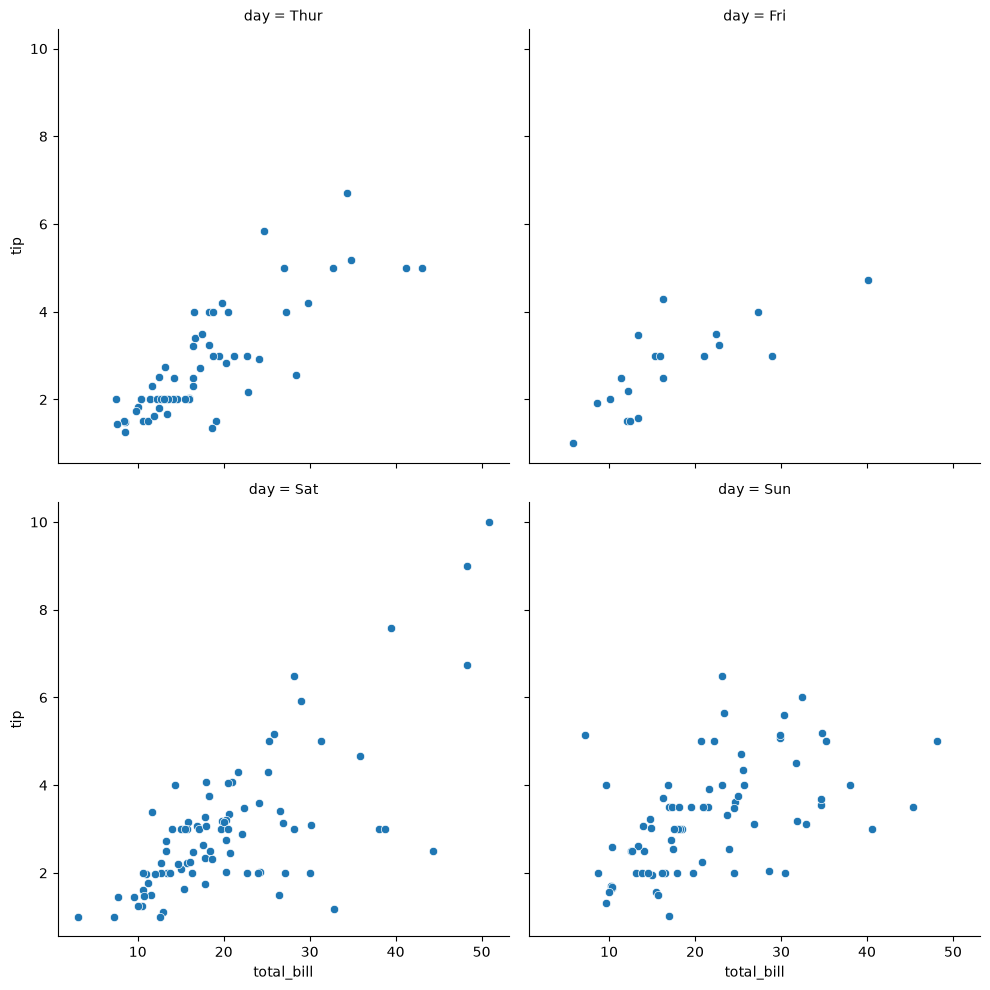

In [31]:
sns.relplot(x='total_bill', y='tip', data=tips, kind='scatter', 
            col='day', col_wrap=2,
            col_order=['Thur', 'Fri', 'Sat', 'Sun'])

### Subgroups with point size

size=

Varying point size is best used if the variable is either a quantitative variable or a categorical variable that represents different levels of something, like 'small', 'medium' and 'large'.


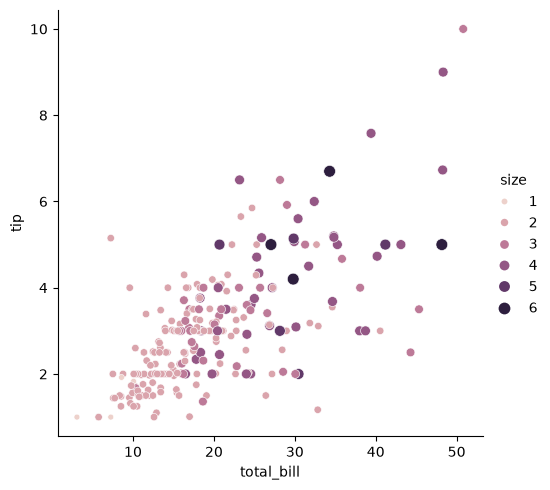

In [32]:
sns.relplot(x='total_bill', y='tip', data=tips,
            kind='scatter', size='size', hue='size')

because we set hue='size' and 'size' is a quantitative variable, Seaborn will automatically color the points different shades of the same color instead of different colors per category value like we saw in previous plots. Now larger groups have both larger and darker points, which provides better contrast and makes the plot easier to read.

## Point style

setting the 'style' parameter to a variable name will use different point styles for each value of the variable

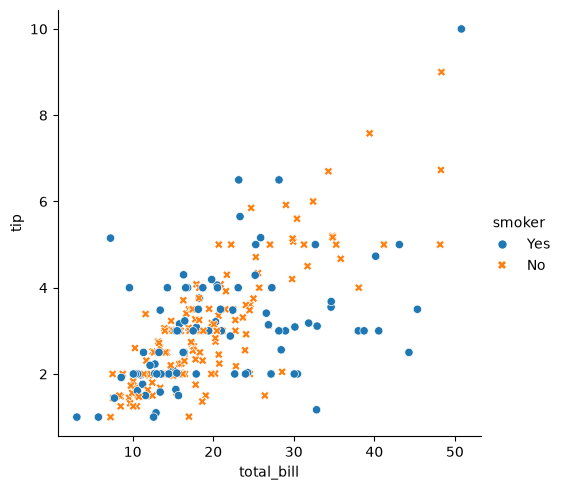

In [33]:
sns.relplot(x='total_bill', y='tip', data=tips, kind='scatter',
            hue='smoker',
            style='smoker')

### Changing point transparency

setting the 'alpha' parameter to a value between 0 and 1 will vary the transparency of the points in the plot, with 0 being completely transparent and 1 being completly non-transparent.

This customization can be useful when you have many overlapping points on the scatterplot, so you can see which areas of the plot have more or less observations.

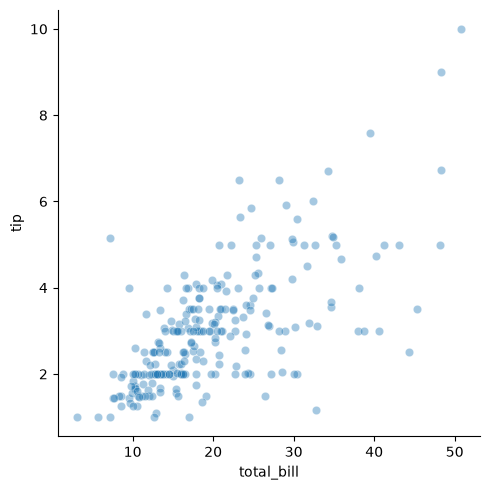

In [34]:
sns.relplot(x='total_bill', y='tip', data=tips, kind='scatter', alpha=0.4)

## Line plots

In seaborn a line plot is also a relation plot.

Line plots are the vsualization of choice when we need to track the same thing over time. For example the value of a company's stock over time.

In [35]:
import kagglehub

path = kagglehub.dataset_download("heesoo37/120-years-of-olympic-history-athletes-and-results")
df = pd.read_csv(f"{path}/athlete_events.csv")

In [36]:
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


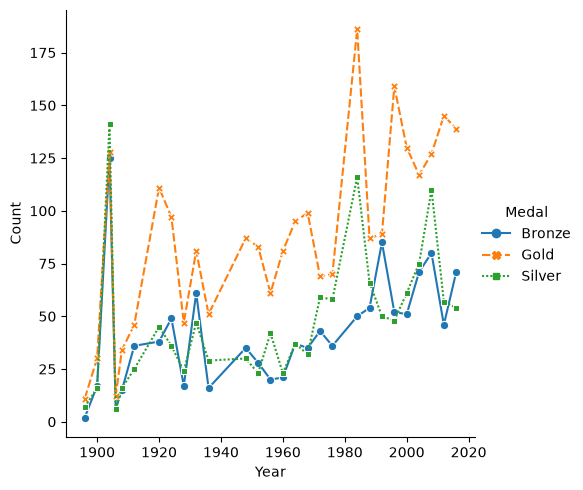

In [37]:
usa_summer = df[
    (df['NOC'] == 'USA') &
    (df['Season'] == 'Summer')]

usa_medals_summer = usa_summer.dropna(subset=['Medal'])

medals_per_type = (
    usa_medals_summer.groupby(['Year', 'Medal'])
    .size()
    .reset_index(name="Count")
)

sns.relplot(data=medals_per_type, kind='line',
             x='Year', y='Count',
             hue='Medal', style='Medal', markers=True)

dashes=False   if you don't want the linestyle to vary between subgroups

### Multiple obsevations per x-value

If a line plot is given multiple observations per x-value, it will aggregate them into a single summary measure. By default it will display the mean. Notice that Seaborn will automatically calculate a confidence interval for the mean, displayed by the shaded region

Replacing confidence interval with standard deviation

errorbar='sd'

or turn of the confidence interval 

errorbar=None

## Categorical plots

Ex. count plots, bars plots
Involve a categorical 
Comparison between groups


catplot()
same advantages as relplot()

category_order = []

sns.catplot(x='how_masculine', data=masculinity_data, kind='count',
order=category_order)


Bar plots look similar to count plots, but instead of the count of observations in each category, they show the MEAN of a quantitative variable among observations in each category.

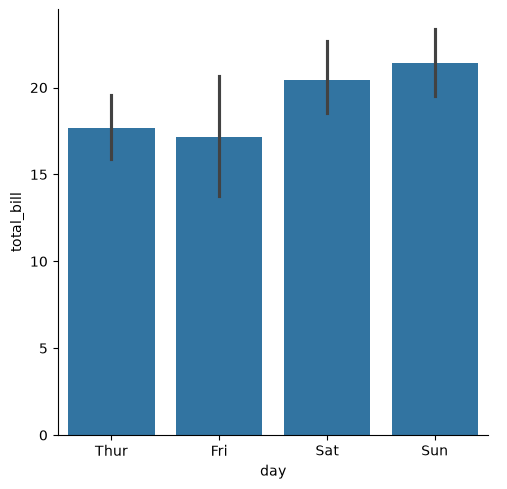

In [38]:
sns.catplot(x='day', y='total_bill', data=tips, kind='bar')

Seaborn automatically shows 95% confidence intervals for these means. Shows  uncertainty about our estimate. Assumes out data is a random sample. Turn of with errobar=None. 
 
NOTE: very different than Matplotlib. Seaborn is desgined for statistical visualization.

## Boxplot

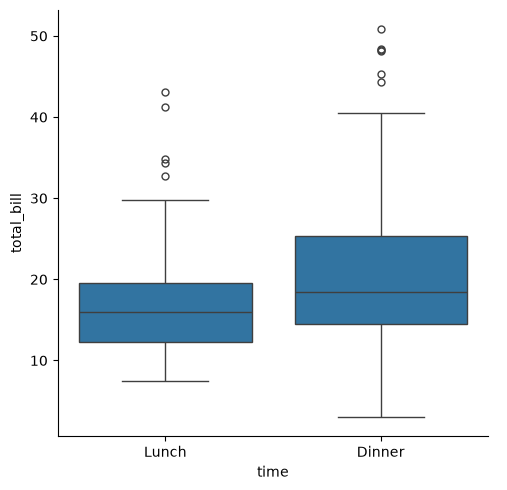

In [ ]:
sns.catplot(x='time', y='total_bill', data=tips, kind='box')

showfliers=False   omitts outlier

you can make the whiskers extend longer than the default 1.5 * the IQR bt setting 
whis=2.0 for example
or pass it a list with lower and upper values whis=[5, 95]
or at min and max values whis=[0,100]. In that case they will cover the whole data, so there will not be any outliers

hue=    to create subgroups/subplots so each boxplot is colored based on it's group

## Point plots

Also categorical. It shows the mean of a quantitative variable for the observations in each category, plotted as a single point. Vertical bars represent the 95% confidence interval for that mean. Shows the level of uncertainty. Assuming our data is a random sample of some population, we can be 95% sure that the TRUE POPULATION MEAN in each group lies within the confidence interval shown.

In a point plot, one axis is a categorical variable, usually the x-axis.

sns.catplot(x='age', y='masculinity_important', data=masculinity_data, hie='feel_masculine', kind='point')

linestyle='none'   removes the lines connecting each point


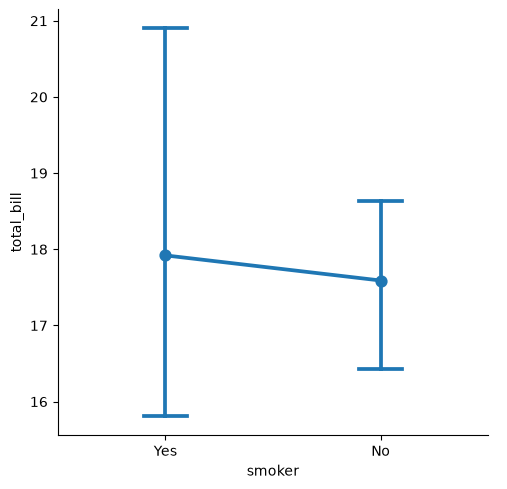

In [43]:
from numpy import median

sns.catplot(x='smoker', y='total_bill', data=tips, kind='point', 
            estimator='median',
            capsize=0.2) 
#to have the points an CI be for median instead of mean
# add caps on the CIs



## Customization

Seaborn has five preset figure styles which change the background and axes of the plot. They change the background and axes of the plots

- 'white' (default, higher level observations)
- 'dark'
- 'whitegrid' (good for seeing specific values)
- 'darkgrid'
- 'ticks'

sns.set_style()

You can change the color of the main elements of the plot with:

sns.set_palette()

There are diverging palettes, for two opposites and neutral middle.

There are sequential palettes, with one color moving from light to dark. They are great to emphasize a variable on a continuous scale. 

You can change the scale of you plot:

sns.set_context()

from smallest to largest:
- 'paper' (default)
- 'notebook'
- 'talk'
- 'poster'

large: for presentations where the audiance is far away



## Titles and labels

Seaborn creates two different types of objects: FacetGrid and AxesSubplots. To find out which object:

g = sns.scatterplot(x='height', y='weight', data=df)
type(g)

FacetGrid   -  relplot() and catplot()  -  can create subplots

AxesSubplot -  scatterplot, counplot()   -  only creates a single plot

### Adding a title to a FacetGrid object

assign the plot to the variable g. Then you can set the title using g.g,g.figure.suptitle('New Title', y=1.3)

### Adding a title to AxesSubplots

assign the plot to g

g.set_title()
y adjusts height

### Titles for subplots

g.set_titles()

### Adding axis labels (for both)

g.set(xlabel="New X Label",
        ylabel="New Y Label")

### Rotating x-axis tick labels (for both)

plt.xticks(rotation=90)


### Changing font size

sns.set(font_scale= )
